In [9]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("treadwear.txt", sep = "\t")
data

,mileage,groove
0,0,394.33
1,4,329.50
2,8,291.00
3,12,255.17
4,16,229.33
5,20,204.83
6,24,179.00
7,28,163.83
8,32,150.33


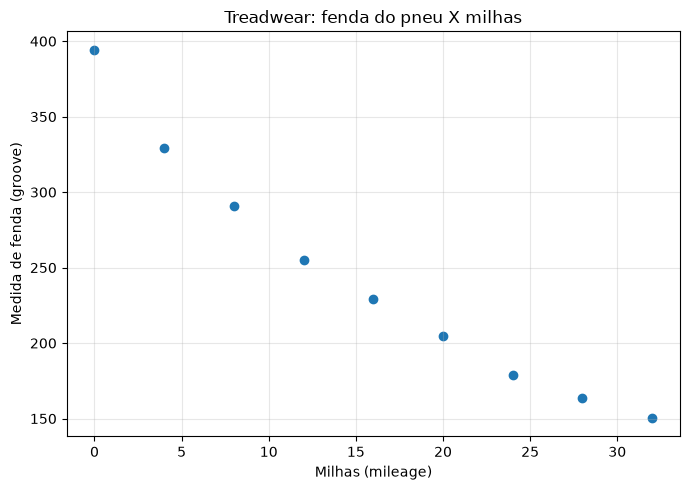

In [13]:
fig, ax = plt.subplots(figsize = (7, 5))

ax.scatter(data["mileage"], data["groove"])
ax.set(
    title = "Treadwear: fenda do pneu X milhas",
    xlabel = "Milhas (mileage)",
    ylabel = "Medida de fenda (groove)"
)
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

In [15]:
import statsmodels.api as sm

x = data["mileage"]
y = data["groove"]

X = sm.add_constant(x)

# Ordinary Least Squares --> Método dos quadrados mínimos
model = sm.OLS(y, X)
result = model.fit()

print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 groove   R-squared:                       0.953
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     140.7
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           6.87e-06
Time:                        20:56:23   Log-Likelihood:                -38.148
No. Observations:                   9   AIC:                             80.30
Df Residuals:                       7   BIC:                             80.69
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        360.6367     11.689     30.854      0.0

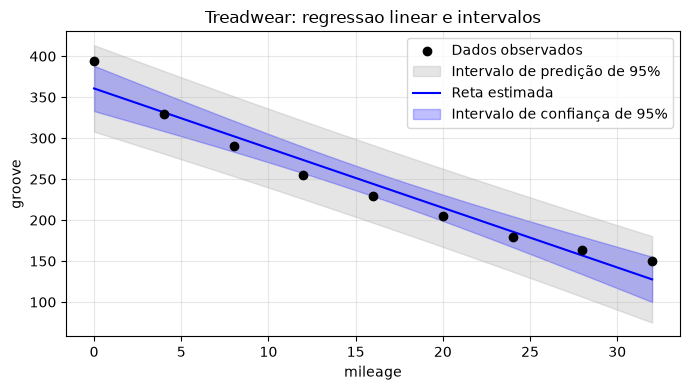

In [29]:
import numpy as np

x_grade = np.linspace(x.min(), x.max(), 200)

X_grade = sm.add_constant(x_grade)

prediction = result.get_prediction(X_grade)
prediction_table = prediction.summary_frame(alpha = 0.05)

fig, ax = plt.subplots(figsize = (7, 4))

ax.scatter(x, y, color = "black", label = "Dados observados", zorder = 3)

# Predição de 95%
ax.fill_between(
    x_grade, 
    prediction_table["obs_ci_lower"], 
    prediction_table["obs_ci_upper"],
    color = "gray", 
    alpha = 0.2, 
    label = "Intervalo de predição de 95%"
)

# Reta dos quadrados minimos
ax.plot(
    x_grade,
    prediction_table["mean"],
    color = "blue",
    label = "Reta estimada"
)

# Intervalo de Confiaça de 95%
ax.fill_between(
    x_grade,
    prediction_table["mean_ci_lower"],
    prediction_table["mean_ci_upper"],
    color = "blue",
    alpha = 0.25,
    label = "Intervalo de confiança de 95%"
)

ax.set(
    title = "Treadwear: regressao linear e intervalos",
    xlabel = "mileage",
    ylabel = "groove"
)

ax.grid(alpha = 0.3)
ax.legend()

plt.tight_layout()
plt.show()

   mileage  observado  predito  residuo
0        0     394.33   360.64    33.69
1        4     329.50   331.51    -2.01
2        8     291.00   302.39   -11.39
3       12     255.17   273.27   -18.10
4       16     229.33   244.15   -14.82
5       20     204.83   215.02   -10.19
6       24     179.00   185.90    -6.90
7       28     163.83   156.78     7.05
8       32     150.33   127.66    22.67


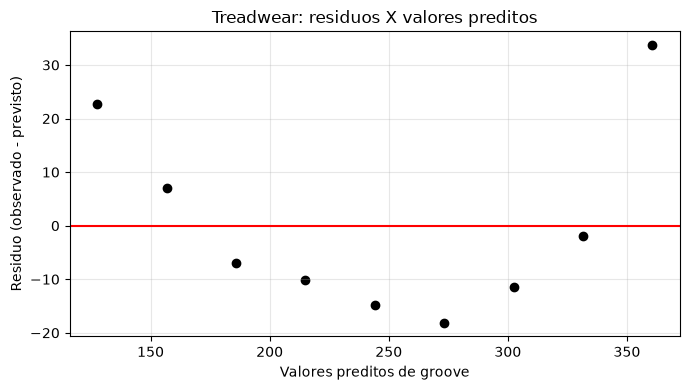

In [33]:
predicted = result.fittedvalues
residual = result.resid

residual_table = pd.DataFrame({
    "mileage": x,
    "observado": y,
    "predito": predicted,
    "residuo": residual
})

print(residual_table.round(2))

fig, ax = plt.subplots(figsize = (7, 4))

ax.scatter(predicted, residual, color = "black")
ax.axhline(y = 0, color = "red", linestyle = "-")

ax.set(
    title= "Treadwear: residuos X valores preditos",
    xlabel = "Valores preditos de groove",
    ylabel = "Residuo (observado - previsto)"
)

ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

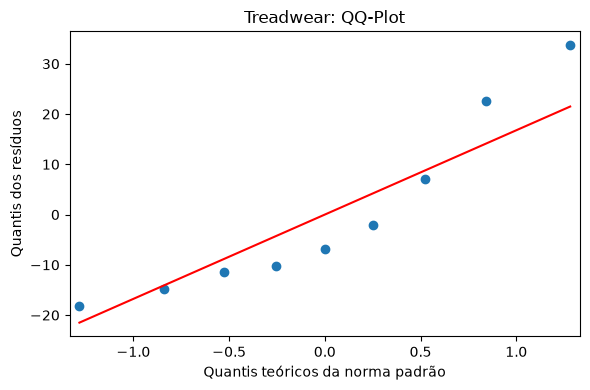

teste


In [37]:
from scipy.stats import norm

fig, ax = plt.subplots(figsize = (6, 4))

sm.qqplot(
    residual,
    dist = norm,
    line = "s",
    ax = ax
)

ax.set(
    title = "Treadwear: QQ-Plot",
    xlabel = "Quantis teóricos da norma padrão",
    ylabel = "Quantis dos resíduos"
)

plt.tight_layout()
plt.show()

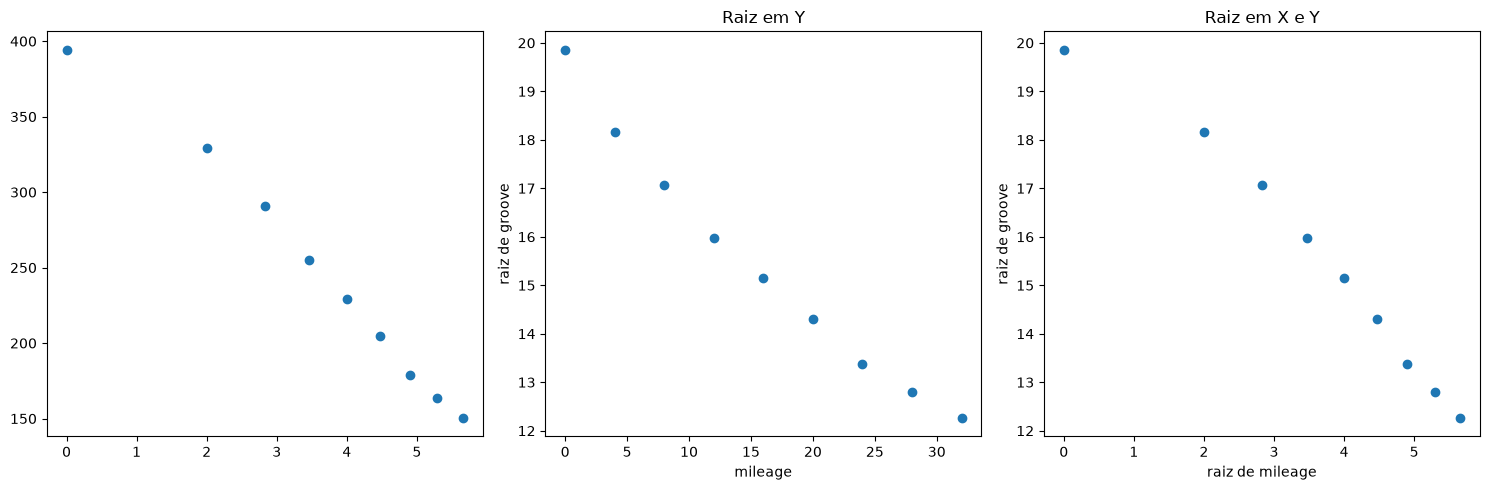

In [42]:
import numpy as np
 
x = data["mileage"]
y = data["groove"]

# raiz quadrada
x_root = np.sqrt(x)
y_root = np.sqrt(y)

fig, axis = plt.subplots(1, 3, figsize = (15, 5))

axis[0].scatter(x_root, y)
axis[1].set(
    title = "Raiz em X",
    xlabel = "raiz de mileage",
    ylabel = "groove"
)

axis[1].scatter(x, y_root)
axis[1].set(
    title = "Raiz em Y",
    xlabel = "mileage",
    ylabel = "raiz de groove"
)

axis[2].scatter(x_root, y_root)
axis[2].set(
    title = "Raiz em X e Y",
    xlabel = "raiz de mileage",
    ylabel = "raiz de groove"
)

plt.tight_layout()
plt.show()

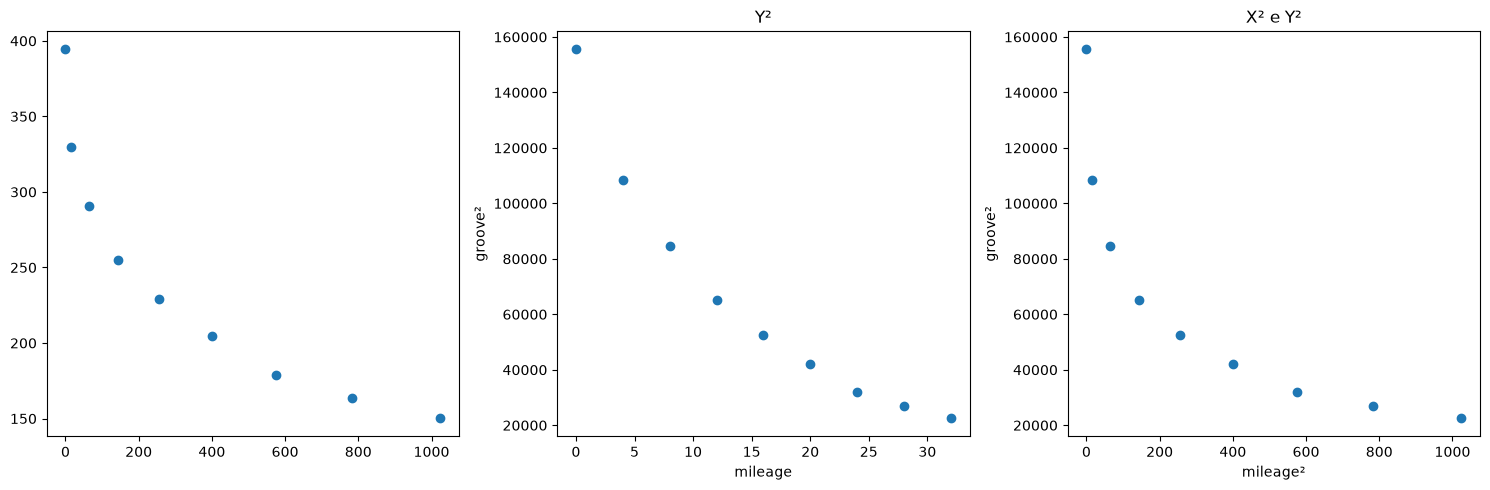

In [43]:

# elevado ao quadrado
x_squared = x ** 2
y_squared = y ** 2

fig, axis = plt.subplots(1, 3, figsize = (15, 5))

axis[0].scatter(x_squared, y)
axis[1].set(
    title = "X²",
    xlabel = "mileage²",
    ylabel = "groove"
)

axis[1].scatter(x, y_squared)
axis[1].set(
    title = "Y²",
    xlabel = "mileage",
    ylabel = "groove²"
)

axis[2].scatter(x_squared, y_squared)
axis[2].set(
    title = "X² e Y²",
    xlabel = "mileage²",
    ylabel = "groove²"
)

plt.tight_layout()
plt.show()

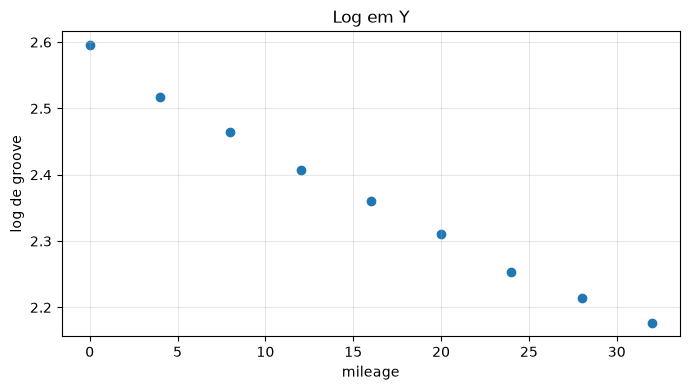

Usando Log os pontos se ajustam melhor do que nas outras alternativas


In [48]:
y_log = np.log10(y)

fig, ax = plt.subplots(figsize = (7,4))

ax.scatter(x, y_log)
ax.set(
    title = "Log em Y",
    xlabel = "mileage",
    ylabel = "log de groove"
)

ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

print("Usando Log os pontos se ajustam melhor do que nas outras alternativas")

                            OLS Regression Results                            
Dep. Variable:                 groove   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                     976.3
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           8.88e-09
Time:                        03:20:51   Log-Likelihood:                 27.570
No. Observations:                   9   AIC:                            -51.14
Df Residuals:                       7   BIC:                            -50.75
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5736      0.008    326.576      0.0

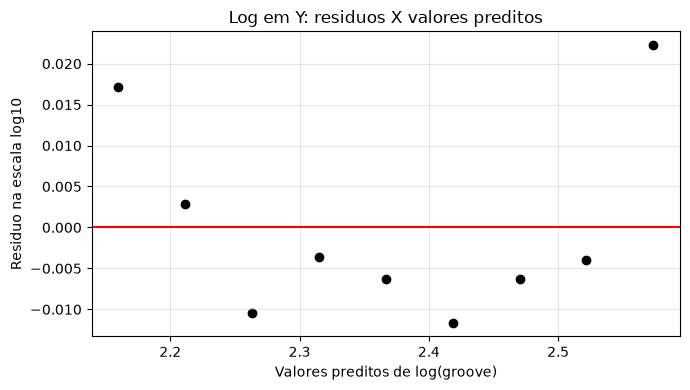

Ainda não eliminou esse padrão em U


In [51]:
X_log = sm.add_constant(x)

model_log = sm.OLS(y_log, X_log)
result_log = model_log.fit()

print(result_log.summary())

fig, ax = plt.subplots(figsize = (7, 4))

ax.scatter(
    result_log.fittedvalues,
    result_log.resid,
    color = "black"
)

ax.axhline(y = 0, color = "red", linestyle = "-")

ax.set(
    title = "Log em Y: residuos X valores preditos",
    xlabel = "Valores preditos de log(groove)",
    ylabel = "Residuo na escala log10"
)
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

print("Ainda não eliminou esse padrão em U")

                            OLS Regression Results                            
Dep. Variable:                 groove   R-squared:                       0.990
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                     670.7
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           3.27e-08
Time:                        03:25:02   Log-Likelihood:                -31.292
No. Observations:                   9   AIC:                             66.58
Df Residuals:                       7   BIC:                             66.98
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          408.0836      6.988     58.401   

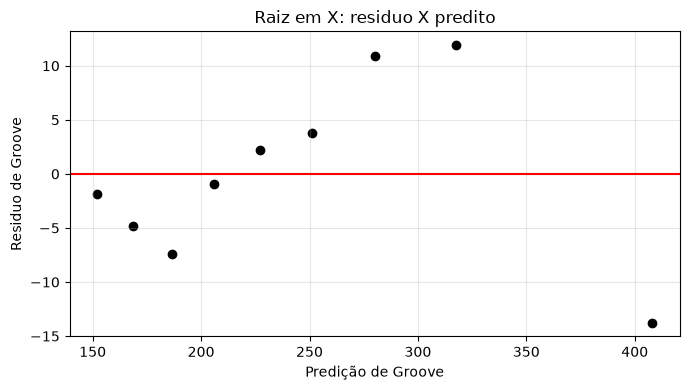

In [53]:
x_root = np.sqrt(x)

x_root = x_root.rename("raiz_mileage")

X_root = sm.add_constant(x_root)
result_root = sm.OLS(y, X_root).fit()

print(result_root.summary())

fig, ax = plt.subplots(figsize = (7, 4))

ax.scatter(
    result_root.fittedvalues,
    result_root.resid,
    color = "black"
)
ax.axhline(y = 0, color = "red", linestyle = "-")

ax.set(
    title = "Raiz em X: residuo X predito",
    xlabel = "Predição de Groove",
    ylabel = "Residuo de Groove"
)
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

print("Apesar do padrão em U diminuir, ainda apresenta instabilidade")

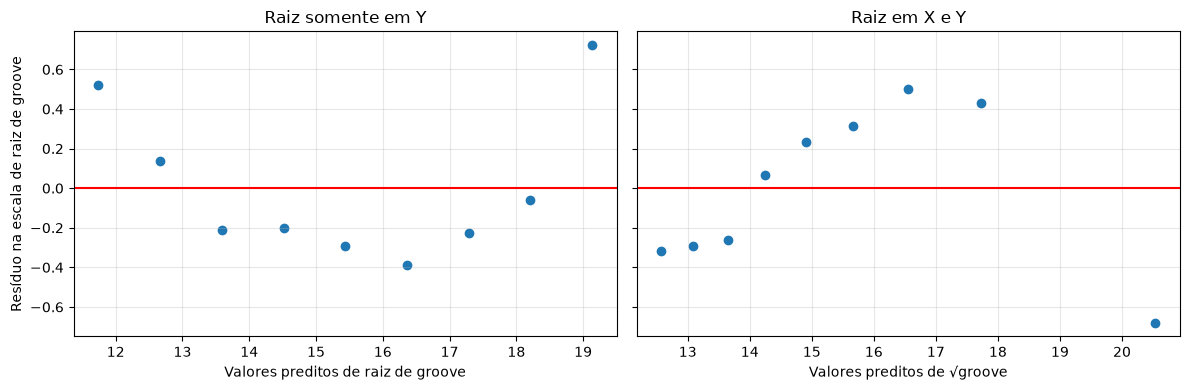

In [56]:
y_root = np.sqrt(y).rename("root_groove")

X_original = sm.add_constant(x)
result_root_y = sm.OLS(y_root, X_original).fit()

X_root = sm.add_constant(x_root)
result_root_both = sm.OLS(y_root, X_root).fit()

fig, axis = plt.subplots(
    1, 2, figsize=(12, 4), sharey=True
)

axis[0].scatter(
    result_root_y.fittedvalues,
    result_root_y.resid
)
axis[0].set(
    title = "Raiz somente em Y",
    xlabel = "Valores preditos de raiz de groove",
    ylabel = "Resíduo na escala de raiz de groove"
)

axis[1].scatter(
    result_root_both.fittedvalues,
    result_root_both.resid
)
axis[1].set(
    title = "Raiz em X e Y",
    xlabel = "Valores preditos de √groove"
)

for ax in axis:
    ax.axhline(y = 0, color = "red", linestyle = "-")
    ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()
